# Naive Bayes Classification


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

In [2]:
# Load the breast-cancer classification dataset.
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print(f"Features: {X.shape[1]}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Classes: {list(data.target_names)}")

Features: 30
Training samples: 455
Testing samples: 114
Classes: [np.str_('malignant'), np.str_('benign')]


In [3]:
model = GaussianNB()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)
print("Class priors:")
print(pd.Series(model.class_prior_, index=data.target_names).round(4))
print("\nFirst five posterior probability predictions:")
probability_table = pd.DataFrame(
    probabilities,
    columns=[f"P({class_name})" for class_name in data.target_names],
)
probability_table.head().round(4)

Class priors:
malignant    0.3736
benign       0.6264
dtype: float64

First five posterior probability predictions:


,P(malignant),P(benign)
0,1.0000,0.0000
1,0.0000,1.0000
2,1.0000,0.0000
3,0.3397,0.6603
4,1.0000,0.0000


In [4]:
# Evaluate the classifier on held-out test data.
metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "F1 score"],
        "Value": [
            accuracy_score(y_test, predictions),
            f1_score(y_test, predictions),
        ],
    }
).set_index("Metric")
metrics.round(4)

,Value
Metric,
Accuracy,0.9386
F1 score,0.9517


In [5]:
print(
    classification_report(
        y_test,
        predictions,
        target_names=data.target_names,
    )
)

matrix = confusion_matrix(y_test, predictions)
print("Confusion matrix:")
print(matrix)

              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

Confusion matrix:
[[38  4]
 [ 3 69]]


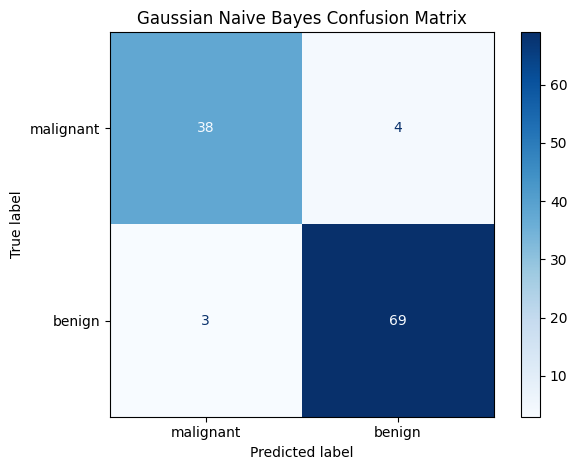

In [6]:
# Visualize correct and incorrect predictions with a confusion matrix.
display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=data.target_names,
)
display.plot(cmap="Blues", values_format="d")
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()